# Data Preparation 
The data comes from here: https://zenodo.org/records/5957394

In [9]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
import rainflow

## Step 1: Extract and reshape the test and train data

In [10]:
# Load the .mat file
df_test = loadmat(r"C:\Users\natal\Downloads\NREL_Testset10000.mat")
df_train = h5py.File(r"C:\Users\natal\Downloads\NREL_Trainset40000.mat", "r")


In [11]:
# Extract the relevant data from the loaded .mat file

# FROM TEST DATASET
Hs_test = df_test['Hs'].flatten()                    # Significant wave height [m]
Tp_test = df_test['Tp'].flatten()                    # Peak period [s]
Vw_mean_test = df_test['Vw_mean'].flatten()          # Wind speed mean[m/s]
Vw_std_test = df_test['Vw_std'].flatten()            # Wind speed standard deviation [m/s]

RPM_test = df_test['Rpm_mean'].flatten()             # Rotational speed [rpm]
Pitch_test = df_test['Pitch_mean'].flatten()         # Pitch angle [deg]

Mxx_test = df_test['Mxx']                            # Bending moment in the x-direction [kNm]
Myy_test = df_test['Myy']                            # Bending moment in the y-direction [kNm]

# FROM TRAIN DATASET
Hs_train = df_train['Hs'][:].flatten()               # Significant wave height [m]
Tp_train = df_train['Tp'][:].flatten()               # Peak period [s]
Vw_mean_train = df_train['Vw_mean'][:].flatten()     # Wind speed mean[m/s]
Vw_std_train = df_train['Vw_std'][:].flatten()       # Wind speed standard deviation [m/s]

RPM_train = df_train['Rpm_mean'][:].flatten()        # Rotational speed [rpm]
Pitch_train = df_train['Pitch_mean'][:].flatten()    # Pitch angle [deg]

Mxx_train = df_train['Mxx']                          # Bending moment in the x-direction [kNm]
Myy_train = df_train['Myy']                          # Bending moment in the y-direction [kNm]

In [ ]:
# Merge the test and train datasets into a single dataset
Hs = np.concatenate((Hs_test, Hs_train))
Tp = np.concatenate((Tp_test, Tp_train))
Vw_mean = np.concatenate((Vw_mean_test, Vw_mean_train))
Vw_std = np.concatenate((Vw_std_test, Vw_std_train))

RPM = np.concatenate((RPM_test, RPM_train))
Pitch = np.concatenate((Pitch_test, Pitch_train))

Mxx = np.concatenate((Mxx_test.ravel(), Mxx_train[:].ravel()))
Myy = np.concatenate((Myy_test.ravel(), Myy_train[:].ravel()))

In [13]:
# Number of simulations
n_sim = len(Hs)
n_samples = len(Mxx) / len(Hs)  # Assuming Mxx and Myy have the same number of samples

# Reshape Mxx and Myy to have shape (n_sim, 30000)
Mxx = Mxx.reshape(n_sim, 30000)
Myy = Myy.reshape(n_sim, 30000)

In [14]:
# Verify the shapes of Mxx and Myy
print(Mxx.shape)
print(Myy.shape)

(49791, 30000)
(49791, 30000)


## Step 2: Compute the resultant moment

$ M_{\mathrm{res}} = \sqrt{M_{xx}^{2} + M_{yy}^{2}}$

In [ ]:
Mres = np.sqrt(Mxx**2 + Myy**2)     # Note, runs around 7 mins

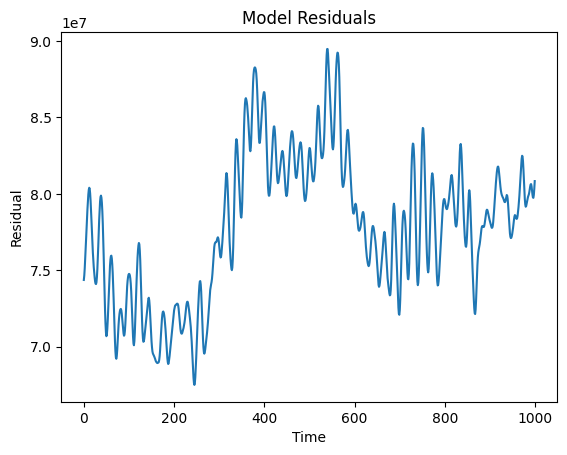

In [16]:
plt.plot(Mres[0,:1000])
plt.xlabel('Time')
plt.ylabel('Residual')
plt.title('Model Residuals')
plt.show()

## Step 3: Create a DEL function
$\mathrm{DEL} = \left(\frac{\sum_i n_i S_i^m}{N_{\mathrm{eq}}}\right)^{1/m}$

In [17]:
import rainflow
import numpy as np

def calculate_del(signal, m=4, Neq=1e7):
    damage_sum = 0.0
    for rng, mean, count, i_start, i_end in rainflow.extract_cycles(signal):
        damage_sum += count * (rng ** m)
    DEL = (damage_sum / Neq) ** (1 / m)

    return DEL

In [18]:
# Test the function with the first signal
del_test = calculate_del(Mres[0])
print(del_test)

1460472.275131001


## Step 4: Loop through all simulations

In [ ]:
# Check the shape of Mres
Mres.shape

(49791, 30000)

In [20]:
from tqdm.auto import tqdm

n_sim = Mres.shape[0]
DEL = np.zeros(n_sim)

for i in tqdm(range(n_sim), desc="Calculating DEL", total=n_sim):
    DEL[i] = calculate_del(Mres[i])

c:\Users\natal\repos\OceanCourses\.ocean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Calculating DEL: 100%|██████████| 49791/49791 [07:50<00:00, 105.74it/s]


In [22]:
print(DEL.shape)

(49791,)


## Step 5: Build final dataframe

In [23]:
print(len(Hs))
print(len(Tp))
print(len(Vw_mean))
print(len(Vw_std))
print(len(RPM))
print(len(Pitch))
print(len(DEL))

49791
49791
49791
49791
49791
49791
49791


In [ ]:
df_final = pd.DataFrame({
    "Hs": Hs,
    "Tp": Tp,
    "Vw_mean": Vw_mean,
    "Vw_std": Vw_std,
    "RPM": RPM,
    "Pitch": Pitch,
})

In [25]:
df_final.head()

,Hs,Tp,Vw_mean,Vw_std,RPM,Pitch,DEL
0,1.248500,4.757716,9.203143,1.749217,9.972552,0.019171,1.460472e+06
1,1.574769,6.303943,11.370682,1.839102,11.694177,1.296207,1.733923e+06
2,0.895745,5.364305,11.460520,1.651695,11.757063,1.184234,1.831648e+06
3,0.638518,7.412787,6.598440,1.438964,8.256958,0.000000,8.610574e+05
4,2.740453,5.828636,15.811478,2.406468,12.093967,10.479204,2.552811e+06


In [26]:
df_final.to_csv("NREL_DEL.csv", index=False)

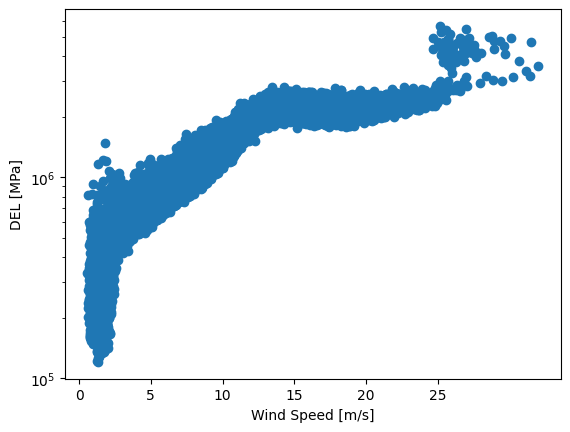

In [27]:
plt.scatter(df_final["Vw_mean"], df_final["DEL"])
plt.xticks(np.arange(0, 30, 5))
plt.xlabel("Wind Speed [m/s]")
plt.ylabel("DEL [MPa]")
plt.yscale("log")